# Experiment 6: Gradient Descent, SGD, Momentum and Adam Comparison

A logistics team models delivery time from distance, traffic, parcel weight and time of day. We first compare optimiser trajectories on a two-dimensional bowl, then train the same small Keras regressor with SGD, momentum and Adam.

**Tools:** NumPy, TensorFlow, Keras, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Implement batch GD, SGD and Momentum on a simple loss surface and plot their paths.  2. Train the same Keras regression architecture with SGD, SGD+Momentum and Adam.  3. Plot loss by epoch.  4. Compare small and excessive learning rates for convergence or divergence.

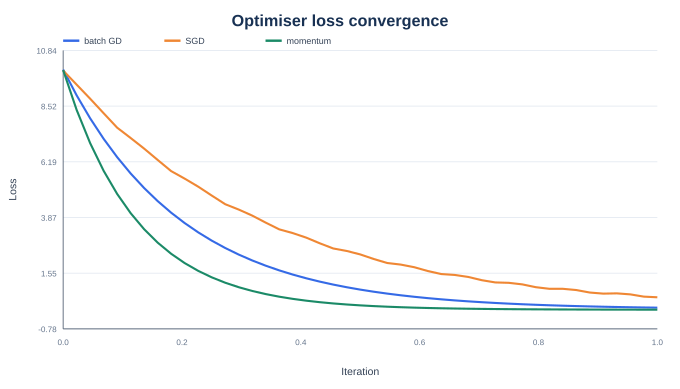

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def grad(w):
    return np.array([2*(w[0]-3), 18*(w[1]+1)])
def loss(w):
    return (w[0]-3)**2 + 9*(w[1]+1)**2

start = np.array([-4.0, 4.0])
paths = {}
for name, method, lr in [("Batch GD", "gd", .08), ("SGD", "sgd", .025), ("Momentum", "momentum", .08)]:
    w = start.copy(); velocity = np.zeros(2); history = [w.copy()]
    for step in range(70):
        g = grad(w) if method != "sgd" else grad(w) + np.random.default_rng(step).normal(0, .4, 2)
        if method == "momentum":
            velocity = .85*velocity + g
            w -= lr*velocity
        else:
            w -= lr*g
        history.append(w.copy())
    paths[name] = np.array(history)

u, v = np.meshgrid(np.linspace(-5, 5, 180), np.linspace(-4, 6, 180))
z = (u-3)**2 + 9*(v+1)**2
plt.figure(figsize=(6, 5))
plt.contour(u, v, z, levels=np.geomspace(.1, 700, 18), norm=LogNorm(), cmap="gray")
for name, path in paths.items():
    plt.plot(path[:,0], path[:,1], marker=".", ms=2, label=name)
plt.scatter([3], [-1], marker="*", s=120, color="red", label="minimum")
plt.title("Optimiser paths on an anisotropic quadratic loss"); plt.legend(); plt.tight_layout(); plt.show()

# Small synthetic delivery-time dataset.
import tensorflow as tf
tf.keras.utils.set_random_seed(6)
rng = np.random.default_rng(6)
X = rng.normal(size=(900, 4)).astype("float32")
y = (18 + 5*X[:,0] + 7*X[:,1] + 2*X[:,2] + 1.5*X[:,3] +
     rng.normal(0, 1.5, len(X))).astype("float32")
X_train, X_val = X[:700], X[700:]
y_train, y_val = y[:700], y[700:]
histories = {}
for name, opt in [
    ("SGD", tf.keras.optimizers.SGD(learning_rate=.03)),
    ("Momentum", tf.keras.optimizers.SGD(learning_rate=.03, momentum=.85)),
    ("Adam", tf.keras.optimizers.Adam(learning_rate=.01))
]:
    model = tf.keras.Sequential([tf.keras.layers.Input((4,)),
        tf.keras.layers.Dense(16, activation="relu"), tf.keras.layers.Dense(1)])
    model.compile(optimizer=opt, loss="mse")
    histories[name] = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                epochs=25, batch_size=32, verbose=0).history
plt.figure(figsize=(7, 4))
for name, h in histories.items():
    plt.plot(h["val_loss"], label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation MSE"); plt.title("Keras optimiser comparison")
plt.grid(alpha=.2); plt.legend(); plt.tight_layout(); plt.show()

# Learning-rate sweep for the same quadratic objective.
for lr in [.08, .35]:
    w = start.copy(); values = []
    for _ in range(25):
        values.append(loss(w)); w -= lr*grad(w)
    print(f"learning rate {lr}: initial loss={values[0]:.2f}, final loss={values[-1]:.2f}, finite={np.isfinite(values[-1])}")